# PART 1: IEEE-CIS Fraud Detection Data Exploration

### 1.1 Data Load and Sample Fraud Rate overview
### 1.2 Transaction Amount Distribution
### 1.3 Categorical Feature Analysis
### 1.4 Missing Data Analysis
### 1.5 Anonymized Feature Correlation Analysis
### 1.6 Part 1 Summary of Findings

### 1.1 Data Load and Class Imbalance overview

In order to conduct data exploration, pandas, numpy and matplotlib python libraries were imported.

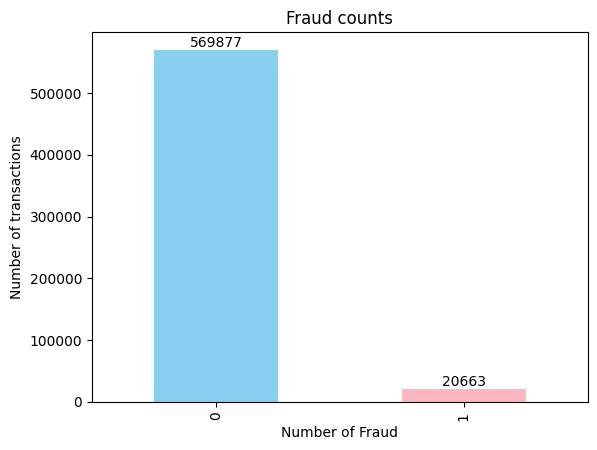

In [13]:
# Importing Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# Label Data Files
train_transaction = pd.read_csv("Data/train_transaction.csv")
train_identity = pd.read_csv("Data/train_identity.csv")

# Merging two databse by identity id by creating a new dataframe
df = train_transaction.merge(train_identity, on="TransactionID", how="left")

#checks
# print("Transaction:", train_transaction.shape)
# print("Identity:   ", train_identity.shape)
# print("Merged:     ", df.shape)

#Counting the fraud using Bar Chart
counts = df["isFraud"].value_counts()
colors = counts.index.map({0: "#89CFF0", 1: "#FFB6C1"})  # baby blue, light pink
fraud_bar = counts.plot(kind="bar", color=colors, title="Fraud counts", xlabel="Number of Fraud", ylabel="Number of transactions")
fraud_bar.bar_label(fraud_bar.containers[0])
plt.show()



Based on the output of Number of Fraud, there seem to be a small number of frauds where in the database there exist 20663 frauds and 569877 that are normal transactions. The percentage of fraud in this database is 3.5% (20663/569877). Please see details in figure 1. 

count    590540.000000
mean        135.027176
std         239.162522
min           0.251000
25%          43.321000
50%          68.769000
75%         125.000000
max       31937.391000
Name: TransactionAmt, dtype: float64


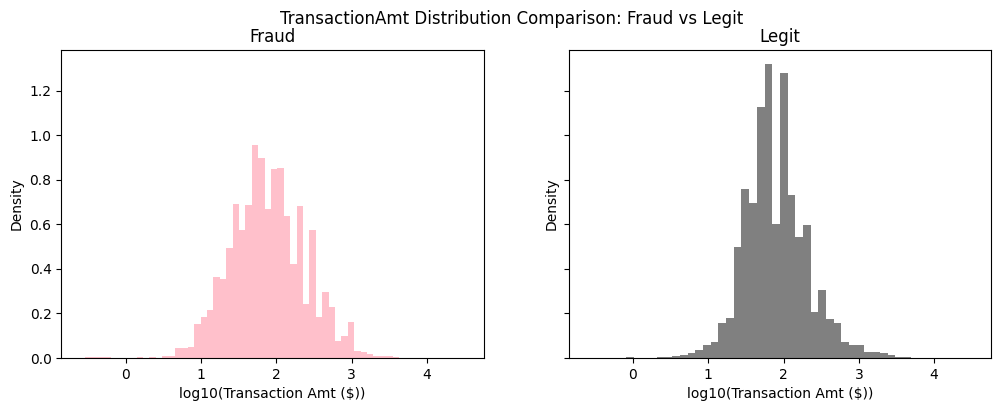

In [14]:
# see the transactionamt summary first
print(df["TransactionAmt"].describe())

# Ploting the histogram to see distribution
# np.log10(df["TransactionAmt"]).plot(kind="hist", bins=50, title="TransactionAmt (raw)", xlabel="Transaction Amount ($)")

fraud = df[df["isFraud"] == 1]
legit = df[df["isFraud"] == 0]

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True, sharey=True)

axes[0].hist(np.log10(fraud["TransactionAmt"]), bins=50, label="fraud", color="pink", density="true")
axes[1].hist(np.log10(legit["TransactionAmt"]), bins=50, label="legit", color="grey", density="true")
axes[0].set_title("Fraud")
axes[1].set_title("Legit")
axes[0].set_xlabel("log10(Transaction Amt ($))")
axes[1].set_xlabel("log10(Transaction Amt ($))")
axes[0].set_ylabel("Density")
axes[1].set_ylabel("Density")

fig.suptitle("TransactionAmt Distribution Comparison: Fraud vs Legit")
plt.show()

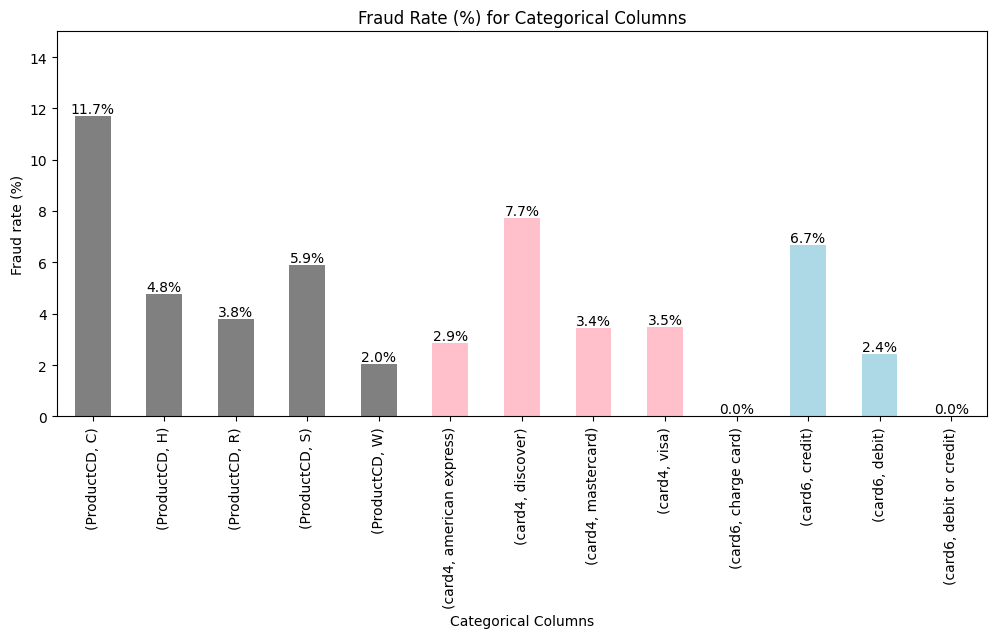

In [15]:
#The 3 categorical columns 
product_fraud_rate = df.groupby("ProductCD")["isFraud"].mean() * 100
card4_fraud_rate = df.groupby("card4")["isFraud"].mean() * 100
card6_fraud_rate = df.groupby("card6")["isFraud"].mean() * 100

product_fraud_rate = product_fraud_rate.round(2)
card4_fraud_rate = card4_fraud_rate.round(2)
card6_fraud_rate = card6_fraud_rate.round(2)

# creating a table
fraud_rates = pd.concat([product_fraud_rate, card4_fraud_rate, card6_fraud_rate],
                      keys=["ProductCD", "card4", "card6"])

#bar Chart
colors = ["grey"] * len(product_fraud_rate) + ["pink"] * len(card4_fraud_rate) + ["lightblue"] * len(card6_fraud_rate)
cat_bar = fraud_rates.plot(kind = "bar", color = colors, figsize=(12, 5), 
                          title = "Fraud Rate (%) for Categorical Columns", 
                          xlabel = "Categorical Columns", 
                          ylabel = "Fraud rate (%)")
cat_bar.set_ylim(0, 15)
cat_bar.bar_label(cat_bar.containers[0], fmt="%.1f%%")
plt.show()


In [16]:
fraud = df[df["isFraud"] == 1]
legit = df[df["isFraud"] == 0]


miss_all   = df.isna().mean() * 100
miss_fraud = fraud.isna().mean() * 100
miss_legit = legit.isna().mean() * 100

miss_all = miss_all.round(2)
miss_fraud = miss_fraud.round(2)
miss_legit = miss_legit.round(2)

# print(miss_all)

empty_table = pd.DataFrame({
    "% Empty For Each Column" : miss_all, 
    "% Empty That Were Fraud" : miss_fraud, 
    "% Empty That Were Non-Fraud" : miss_legit
})

empty_table = empty_table[empty_table["% Empty For Each Column"] > 90]

empty_table


,% Empty For Each Column,% Empty That Were Fraud,% Empty That Were Non-Fraud
dist2,93.63,81.94,94.05
D7,93.41,71.98,94.19
id_07,99.13,97.94,99.17
id_08,99.13,97.94,99.17
id_18,92.36,81.92,92.74
id_21,99.13,97.94,99.17
id_22,99.12,97.94,99.17
id_23,99.12,97.94,99.17
id_24,99.20,98.05,99.24
id_25,99.13,97.98,99.17


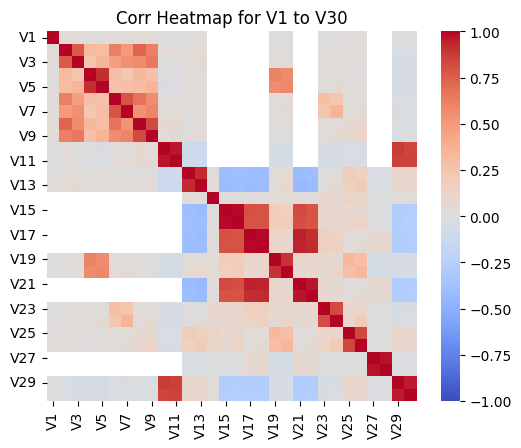

In [17]:
import seaborn as sns
v_subset = [f"V{i}" for i in range (1, 31)]

sns.heatmap(df[v_subset].corr(), cmap="coolwarm", vmin=-1, vmax=1, center=0, square=True)
plt.title("Corr Heatmap for V1 to V30")

plt.show()



In [18]:
v_all = [f"V{i}" for i in range (1, 340)]

v_table = pd.DataFrame({
    "Corr with isFraud": df[v_all].corrwith(df["isFraud"]),
    "Fraud mean":        fraud[v_all].mean(),
    "Non-fraud mean":    legit[v_all].mean(),
})
v_table = v_table.reindex(v_table["Corr with isFraud"].abs().sort_values(ascending=False).index)
v_table.head(10).round(2)

,Corr with isFraud,Fraud mean,Non-fraud mean
V257,0.38,2.96,1.11
V246,0.37,2.49,1.07
V244,0.36,1.99,1.04
V242,0.36,1.93,1.04
V201,0.33,2.75,1.02
V200,0.32,2.48,1.00
V189,0.31,1.87,0.97
V188,0.30,1.71,0.96
V258,0.30,3.40,1.17
V45,0.28,2.21,1.08


# PART 2: Isolation Forest Sensitivity and Feature Ablation Analysis

### 2.1 E0 Baseline Model
### 2.2 E1 Sensitivity to Feature Subsampling (max_features)
### 2.3 E2 Feature Ablation — Transaction Amount Only
### 2.4 E3 Feature Ablation — Card Features Only
### 2.5 E4 Feature Ablation — Temporal Features Only (Diagnostic)
### 2.6 Part 2 Summary of Findings

In preparation of the model evaluations, the following set up includes required models from python libraries and creating unlabeled training data.

In [23]:
# TASK 3 PART TWO ---------------------------------------

#import IsolationForest
from sklearn.ensemble import IsolationForest
from IPython.display import display
import time
from sklearn.metrics import roc_auc_score, average_precision_score

# Database used for learning
# + only uses col that have numbers (don't want categorical)
# fill in empty cells
newdf = df[train_transaction.columns].drop(columns="isFraud").select_dtypes(include="number").fillna(-999)

# Results table for every experiment in Part 2 (one row per experiment)
all_results = pd.DataFrame(columns=["ROC-AUC", "PR-AUC", "Processing Time (s)"], dtype=float)



### 2.1 E0 Baseline Model
The isolationforest baseline model was fitting without manipulating any parameters. In order to evaluate the performance, ROC AUC score is calculated and the top 10 anomalous transactions is pulled.

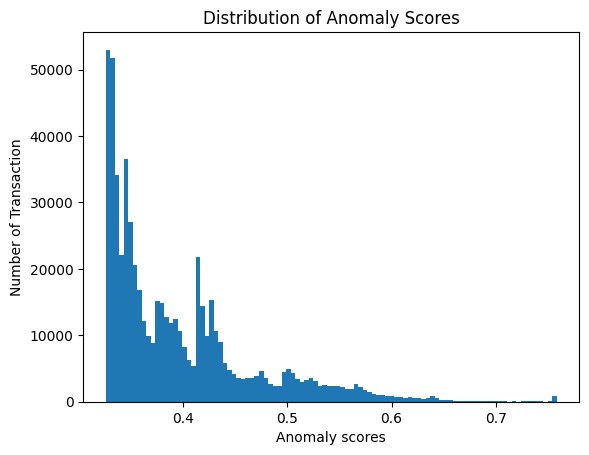

,TransactionAmt,ProductCD,card4,card6,anomaly_score,isFraud
560471,110.0,S,mastercard,credit,0.758096,0
559747,110.0,S,mastercard,credit,0.758096,0
559746,110.0,S,mastercard,credit,0.758096,0
561451,106.0,S,mastercard,credit,0.758096,0
560473,110.0,S,mastercard,credit,0.758096,0
559938,110.0,S,mastercard,credit,0.758096,0
559766,110.0,S,mastercard,credit,0.758096,0
559742,110.0,S,mastercard,credit,0.758096,0
559613,106.0,S,mastercard,credit,0.758096,0
559739,110.0,S,mastercard,credit,0.758096,0


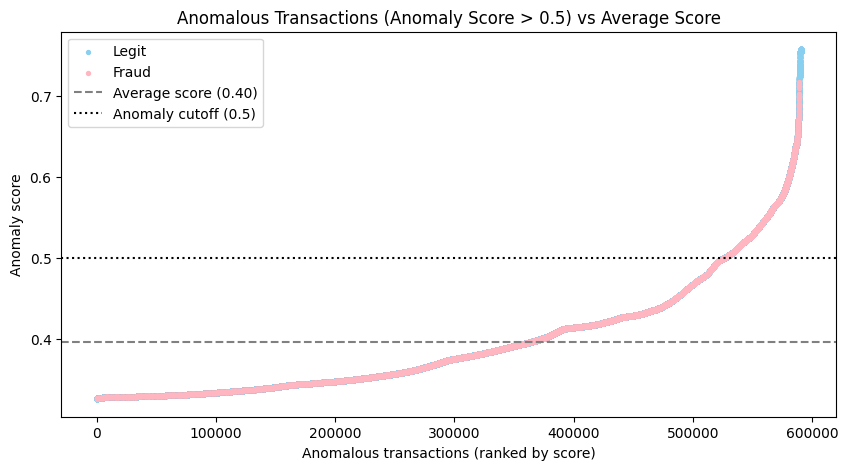

E0 Baseline ROC-AUC: 0.751


In [22]:
# E0: Baseline Isolation Forest (Default Parameters)
start = time.perf_counter() #start of process time tracker
isolated = IsolationForest(random_state=100)
isolated.fit(newdf)
e0_scores = -isolated.score_samples(newdf)
end = time.perf_counter() #end of process time tracker

# save E0 results to the results table
all_results.loc["E0: Baseline"] = [roc_auc_score(df["isFraud"], e0_scores),
                                   average_precision_score(df["isFraud"], e0_scores),
                                   end - start]

# copy of the original df so the anomaly score doesn't get added to df
tempdf = df.copy()

# Create a new col in tempdf that stores all of the anomaly score 
tempdf["anomaly_score"] = -isolated.score_samples(newdf)

# Finding top 10 most anomalous transactions 
top10 = tempdf.sort_values("anomaly_score", ascending=False).head(10)

#finding the dirstribution of the anomaly scores
# higher anomaly score = isolated in few splits = unusual
# anomaly score = 0.5 = average number of splits
tempdf["anomaly_score"].plot(kind="hist", bins=100, 
                     title = "Distribution of Anomaly Scores",
                     xlabel = "Anomaly scores",
                     ylabel = "Number of Transaction")
plt.show()

display(top10[["TransactionAmt", "ProductCD", "card4", "card6", "anomaly_score", "isFraud"]])



# Scatter: how far the anomalous transactions (score > 0.5) are from the average score
mean_score = tempdf["anomaly_score"].mean()
anomalous = tempdf.sort_values("anomaly_score").reset_index(drop=True)
anom_legit = anomalous[anomalous["isFraud"] == 0]
anom_fraud = anomalous[anomalous["isFraud"] == 1]

plt.figure(figsize=(10, 5))
plt.scatter(anom_legit.index, anom_legit["anomaly_score"], s=8, color="#89CFF0", label="Legit")
plt.scatter(anom_fraud.index, anom_fraud["anomaly_score"], s=8, color="#FFB6C1", label="Fraud")
plt.axhline(mean_score, color="grey", linestyle="--", label=f"Average score ({mean_score:.2f})")
plt.axhline(0.5, color="black", linestyle=":", label="Anomaly cutoff (0.5)")
plt.title(f"Anomalous Transactions (Anomaly Score > 0.5) vs Average Score" )
plt.xlabel("Anomalous transactions (ranked by score)")
plt.ylabel("Anomaly score")
plt.legend()
plt.show()

# ROC-AUC of the baseline model (uses all transactions, not just the anomalous ones)
e0_roc_auc = roc_auc_score(tempdf["isFraud"], tempdf["anomaly_score"])
print(f"E0 Baseline ROC-AUC: {e0_roc_auc:.3f}")

### 2.2 E1 Sensitivity to Feature Subsampling (max_features)


,ROC-AUC,PR-AUC,Processing Time (s)
max_features,,,
0.10,0.753,0.100,19.374
0.25,0.754,0.097,24.088
0.50,0.752,0.097,40.185
0.75,0.748,0.097,57.029
1.00,0.751,0.094,9.670


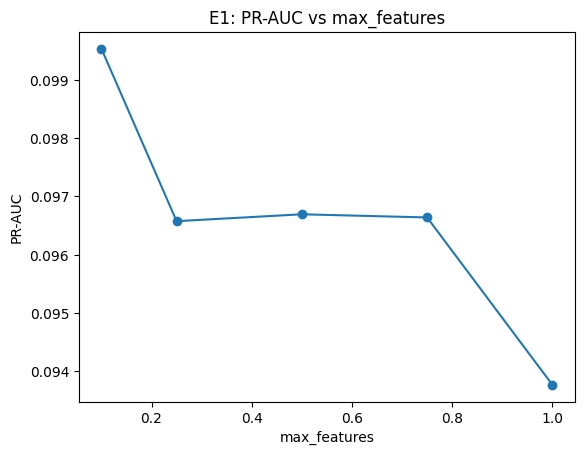

In [24]:
# E1: Running Different Max_Features Inputs

max_feature_values = [0.1, 0.25, 0.5, 0.75, 1.0]

# empty table: one row for each max_features value
e1_resultsdf = pd.DataFrame(index=max_feature_values, columns=["ROC-AUC", "PR-AUC", "Processing Time (s)"])
e1_resultsdf.index.name = "max_features"

i = 0
while i < len(max_feature_values):
    mf = max_feature_values[i]

    # fit the model + score every transaction, timing both
    start = time.perf_counter() # start of measurements of model train time
    model = IsolationForest(max_features=mf, random_state=100)
    model.fit(newdf)
    scores = -model.score_samples(newdf) # calculate the anomaly score
    end = time.perf_counter() # end of measurements of model train time

    # add the results to the table
    e1_resultsdf.loc[mf, "ROC-AUC"] = roc_auc_score(df["isFraud"], scores)
    e1_resultsdf.loc[mf, "PR-AUC"] = average_precision_score(df["isFraud"], scores)
    e1_resultsdf.loc[mf, "Processing Time (s)"] = end - start

    # save this row to the results table
    all_results.loc[f"E1: max_features={mf}"] = e1_resultsdf.loc[mf]

    i += 1

e1_resultsdf = e1_resultsdf.astype(float) # converts all columns to  regular decimal numbers
display(e1_resultsdf.round(3))

# Line chart: PR-AUC vs max_features
e1_resultsdf["PR-AUC"].plot(kind="line", marker="o",
                            title="E1: PR-AUC vs max_features",
                            xlabel="max_features",
                            ylabel="PR-AUC")
plt.show()

### 2.3 E2 Feature Ablation — Transaction Amount Only


,ROC-AUC,PR-AUC,Processing Time (s)
E2: TransactionAmt only,0.607682,0.04753,6.857682


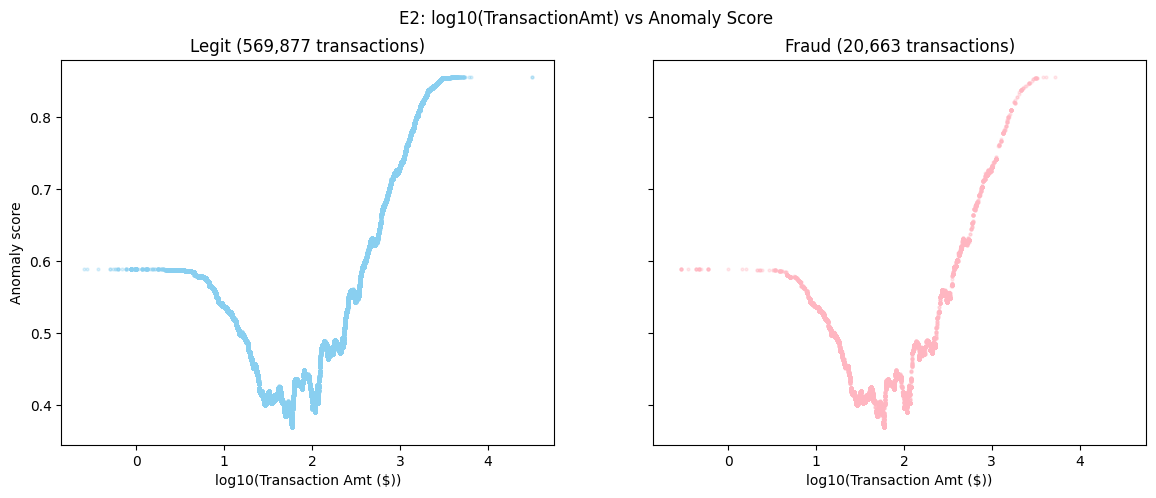

In [28]:
# E2: only looking at TransactionAmt
start = time.perf_counter() #start of process time tracker
e2_model = IsolationForest(random_state=100)
e2_model.fit(newdf[["TransactionAmt"]])
e2_scores = -e2_model.score_samples(newdf[["TransactionAmt"]]) #anomaly score
end = time.perf_counter() #end of process time tracker

# save E2 results to the results table
all_results.loc["E2: TransactionAmt only"] = [roc_auc_score(df["isFraud"], e2_scores),
                                              average_precision_score(df["isFraud"], e2_scores),
                                              end - start]
display(all_results.loc[["E2: TransactionAmt only"]].round(3))

# table for the plot: log amount, anomaly score, fraud label
e2df = pd.DataFrame({
    "log_amt": np.log10(df["TransactionAmt"]),
    "anomaly_score": e2_scores,
    "isFraud": df["isFraud"],
})
e2_legit = e2df[e2df["isFraud"] == 0]
e2_fraud = e2df[e2df["isFraud"] == 1]

# Scatter: log10(amount) vs anomaly score, coloured by fraud
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)

axes[0].scatter(e2_legit["log_amt"], e2_legit["anomaly_score"], s=4, alpha=0.3, color="#89CFF0")
axes[0].set_title(f"Legit ({len(e2_legit):,} transactions)")
axes[1].scatter(e2_fraud["log_amt"], e2_fraud["anomaly_score"], s=4, alpha=0.3, color="#FFB6C1")
axes[1].set_title(f"Fraud ({len(e2_fraud):,} transactions)")

for ax in axes:
    ax.set_xlabel("log10(Transaction Amt ($))")
axes[0].set_ylabel("Anomaly score")

fig.suptitle("E2: log10(TransactionAmt) vs Anomaly Score")
plt.show() 

### 2.4 E4 Feature Ablation — Temporal Features Only (Diagnostic)


,ROC-AUC,PR-AUC,Processing Time (s)
E3: TransactionDT only,0.540438,0.045756,4.620771


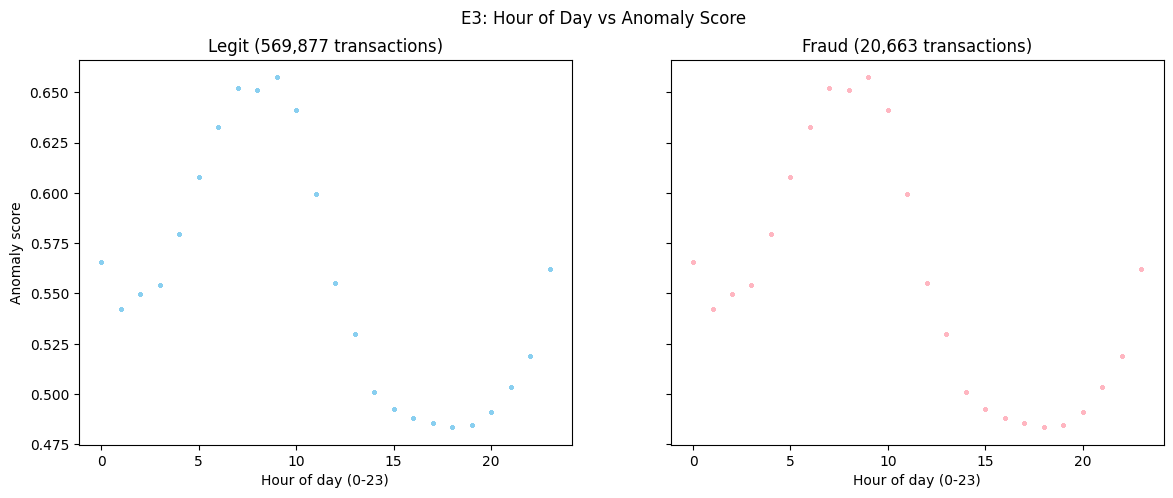

In [40]:
# E3: Only looking at TransactionDT (Only flag transactions at unusual times)

# TransactionDT is in seconds -> convert to hour of day (0-23)
# kept in its own table so the original df doesn't change
e3df = pd.DataFrame({"hour": (df["TransactionDT"] // 3600) % 24}) # only considers within 24 hour

start = time.perf_counter() #start of process time tracker
e3_model = IsolationForest(random_state=100)
e3_model.fit(e3df)
e3_scores = -e3_model.score_samples(e3df) #anomaly score
end = time.perf_counter() #end of process time tracker

# save E2 results to the results table
all_results.loc["E3: TransactionDT only"] = [roc_auc_score(df["isFraud"], e3_scores),
                                              average_precision_score(df["isFraud"], e3_scores),
                                              end - start]
display(all_results.loc[["E3: TransactionDT only"]].round(3))

# table for the plot: hour of day, anomaly score, fraud label
e3_plotdf = pd.DataFrame({
    "hour": e3df["hour"],
    "anomaly_score": e3_scores,
    "isFraud": df["isFraud"],
})
e3_legit = e3_plotdf[e3_plotdf["isFraud"] == 0]
e3_fraud = e3_plotdf[e3_plotdf["isFraud"] == 1]

# Scatter: Hour of day vs anomaly score, coloured by fraud
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)

axes[0].scatter(e3_legit["hour"], e3_legit["anomaly_score"], s=4, alpha=0.3, color="#89CFF0")
axes[0].set_title(f"Legit ({len(e3_legit):,} transactions)")
axes[1].scatter(e3_fraud["hour"], e3_fraud["anomaly_score"], s=4, alpha=0.3, color="#FFB6C1")
axes[1].set_title(f"Fraud ({len(e3_fraud):,} transactions)")

for ax in axes:
    ax.set_xlabel("Hour of day (0-23)")
axes[0].set_ylabel("Anomaly score")

fig.suptitle("E3: Hour of Day vs Anomaly Score")
plt.show()


### 2.5 E3 Feature Ablation — Card Features Only


,ROC-AUC,PR-AUC,Processing Time (s)
E4: Card only,0.655735,0.070403,7.159665


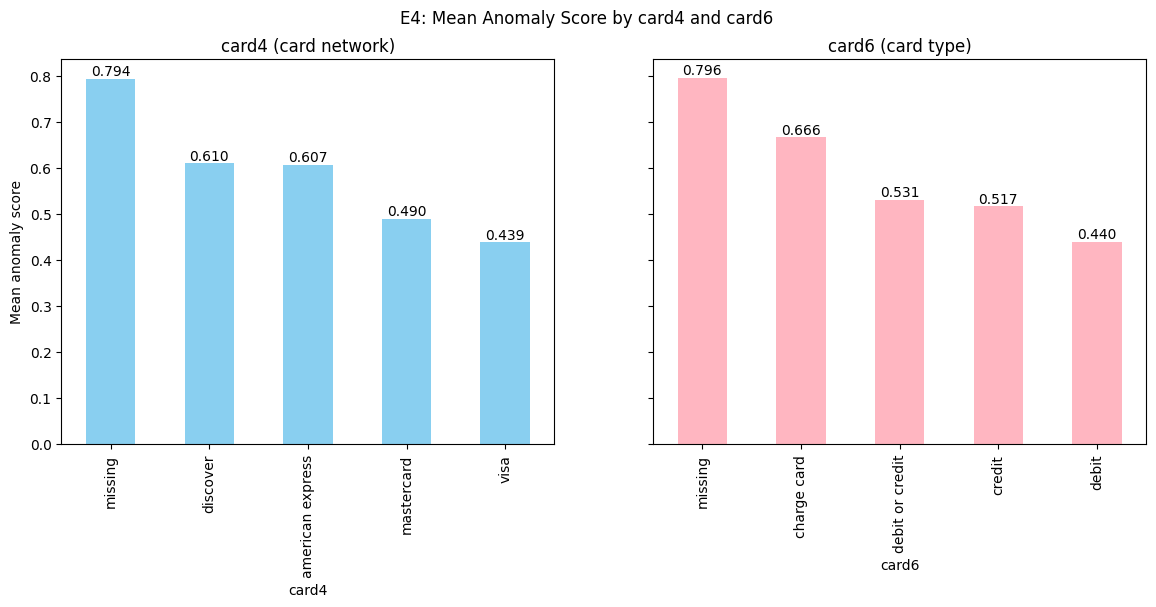

In [41]:
# E4: Only looking at card card1-card3, card4-card6 (NOTE: card 4 and 6 are categorical)

# card4 (visa, mastercard, ...) and card6 (debit, credit, ...) are text -> convert each category to a number
# empty cells become their own "missing" category
card4_codes = df["card4"].fillna("missing").astype("category").cat.codes
card6_codes = df["card6"].fillna("missing").astype("category").cat.codes

# kept in its own table so the original df doesn't change
e4df = pd.DataFrame({
    "card1": newdf["card1"],
    "card2": newdf["card2"],
    "card3": newdf["card3"],
    "card4": card4_codes,
    "card5": newdf["card5"],
    "card6": card6_codes,
})

start = time.perf_counter() #start of process time tracker
e4_model = IsolationForest(random_state=100)
e4_model.fit(e4df)
e4_scores = -e4_model.score_samples(e4df) #anomaly score
end = time.perf_counter() #end of process time tracker

# save E4 results to the results table
all_results.loc["E4: Card only"] = [roc_auc_score(df["isFraud"], e4_scores),
                                    average_precision_score(df["isFraud"], e4_scores),
                                    end - start]
display(all_results.loc[["E4: Card only"]].round(3))


# table for the plot: card type (text), anomaly score, fraud label
e4_plotdf = pd.DataFrame({
    "card4": df["card4"].fillna("missing"),
    "card6": df["card6"].fillna("missing"),
    "anomaly_score": e4_scores,
    "isFraud": df["isFraud"],
})

# Bar chart: mean anomaly score by card4 and card6
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

card4_mean = e4_plotdf.groupby("card4")["anomaly_score"].mean().sort_values(ascending=False)
card4_bar = card4_mean.plot(kind="bar", ax=axes[0], color="#89CFF0",
                            title="card4 (card network)", xlabel="card4", ylabel="Mean anomaly score")
card4_bar.bar_label(card4_bar.containers[0], fmt="%.3f")

card6_mean = e4_plotdf.groupby("card6")["anomaly_score"].mean().sort_values(ascending=False)
card6_bar = card6_mean.plot(kind="bar", ax=axes[1], color="#FFB6C1",
                            title="card6 (card type)", xlabel="card6")
card6_bar.bar_label(card6_bar.containers[0], fmt="%.3f")

fig.suptitle("E4: Mean Anomaly Score by card4 and card6")
plt.show()
